# Baseline: XGBoost on per-field season features

Input: `data/merged_barc.parquet` from `preprocessing/merge_features.ipynb` (one row per field, date and sensor),
and `data/s1_barc.parquet` from `python preprocessing/loader.py --gpkg ... --months 6 11 --s1-only` (Sentinel-1 radar).
Labels are per field and year, so the time series is first reduced to **one row per field-year**.

1. Clean the series and build season features per field-year (no labels involved)
2. Join the Grain/Silage labels (44 field-years, 12 Silage)
3. Validate two ways: leave-one-year-out, and grouped by field
4. Compare XGBoost with a one-feature timing rule, with the earlier Sentinel-2-only version, and with radar added

With 44 samples the scores are rough estimates. Read them with the fold counts and the intervals next to them.

**What changed from the first version, and why**

| Change | Reason | Uses labels? |
|---|---|---|
| Landsat readings are added to the Sentinel-2 series, after removing the sensor offset | Fills cloud gaps around harvest (2022: no clear Sentinel-2 scene Aug 18 to Sep 15), so the drop date is sharper | No. The offset is the median difference on field-days seen by both sensors |
| Isolated spikes and impossible NDVI values are removed | Undetected cloud and shadow create false "drops" and a false peak (some readings had NDVI above 1) | No |
| Each model is the average of 10 XGBoost seeds | With 44 rows, one seed's row and column sampling moves the score by a field or two | No |
| Sentinel-1 radar features are added **as a comparison only** (`xgboost + S1 radar`) | Radar sees through cloud and responds to plant structure. On these 44 field-years it did not clearly help, so the main model stays optical | No |
| ROC AUC, average precision, repeated field splits and bootstrap intervals are reported | One confusion matrix at one threshold is too coarse for 44 rows | Scoring only |

**Kept fixed on purpose:** the feature definitions, the XGBoost settings and the 0.5 threshold are the same as in the first version.
Nothing was tuned against the 44 labels, because every choice made by looking at these scores would inflate them.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, f1_score, roc_auc_score
from sklearn.model_selection import LeaveOneGroupOut, StratifiedGroupKFold
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Add the repo root to the import path so the notebook works from any location
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "preprocessing" / "loader.py").exists())
sys.path.insert(0, str(ROOT))
from preprocessing.loader import barc_labels

GPKG = ROOT / "04_Evaluation" / "BARC_Corn.2021-2023.gpkg"
SEED = 0

merged = pd.read_parquet(ROOT / "data" / "merged_barc.parquet")
print(merged.shape)

(14689, 38)


## 1. Features per field-year

**Series cleaning (label-free).**
- Landsat NDVI, NDTI and NDMI are shifted by the median Landsat minus Sentinel-2 difference, measured on field-days that both sensors saw (all 83 fields).
  Without this, mixing the two would add a fake step to the curve.
- When both sensors saw a field on the same day, the Sentinel-2 reading is kept.
- A reading is dropped when its NDVI is outside (-0.2, 1.0), or when it departs by more than 0.12 from **both** neighbours in the same direction
  (neighbours within 12 days). A real harvest stays low afterwards, so it is not removed.

| Feature | Meaning | Hypothesis |
|---|---|---|
| `ndvi_m07` ... `ndvi_m11`, `ndti_*`, `ndmi_*` | monthly medians | shape of the season |
| `peak_ndvi`, `peak_doy` | highest NDVI, June to September | crop vigour and timing |
| `drop_doy` | first day after the peak with NDVI below half the peak | harvest date: Silage earlier |
| `ndvi_before_drop` | last NDVI seen before the drop | Silage is cut while still green |
| `drop_gap_days` | days between those two readings | how uncertain `drop_doy` is (clouds) |
| `max_drop_rate` | steepest NDVI fall per day after the peak | cutting is abrupt, dry-down is gradual |
| `ndti_post`, `ndvi_post` | medians in the 30 days from the drop | Grain leaves more residue (higher NDTI) |

`farm`, area and location are left out on purpose: they could identify BARC's silage fields without saying anything about harvest.
CDL class is left out for the same reason: it is a crop-type map, not evidence of how the field was harvested.


In [2]:
MONTHS = [7, 8, 9, 10, 11]
HALF = 0.5          # the drop is the first reading below HALF * peak NDVI
POST_DAYS = 30
INDICES = ["ndvi", "ndti", "ndmi"]
SPIKE_TOL, SPIKE_WINDOW = 0.12, 12      # NDVI units, days


def sensor_offsets(m):
    # Median Landsat minus Sentinel-2 difference on field-days seen by both. No labels.
    s2 = m[m["sensor"] == "S2"].set_index(["field_id", "date"])[INDICES]
    ls = m[m["sensor"] == "LANDSAT"].set_index(["field_id", "date"])[INDICES]
    both = s2.join(ls, how="inner", lsuffix="_s2", rsuffix="_ls")
    return {c: float((both[f"{c}_ls"] - both[f"{c}_s2"]).median()) for c in INDICES}, len(both)


def despike(g):
    # Drop readings that jump away from both neighbours in the same direction (cloud, shadow, haze)
    g = g[(g["ndvi"] > -0.2) & (g["ndvi"] < 1.0)].sort_values("date").reset_index(drop=True)
    for _ in range(2):
        v, d = g["ndvi"].values, g["doy"].values
        keep = np.ones(len(g), bool)
        for i in range(1, len(g) - 1):
            if d[i] - d[i - 1] <= SPIKE_WINDOW and d[i + 1] - d[i] <= SPIKE_WINDOW:
                left, right = v[i] - v[i - 1], v[i] - v[i + 1]
                keep[i] = not ((left < -SPIKE_TOL and right < -SPIKE_TOL) or (left > SPIKE_TOL and right > SPIKE_TOL))
        g = g[keep].reset_index(drop=True)
    return g


def fused_series(m):
    # Sentinel-2 plus offset-corrected Landsat, one reading per field-day, spikes removed
    m = m[m["ndvi"].notna()].copy()
    offsets, n_pairs = sensor_offsets(m)
    landsat = m["sensor"] == "LANDSAT"
    for c in INDICES:
        m.loc[landsat, c] -= offsets[c]
    m = (m.sort_values(["field_id", "date", "sensor"], ascending=[True, True, False])     # S2 first
          .drop_duplicates(["field_id", "date"]))
    out = pd.concat([despike(g) for _, g in m.groupby(["field_id", "year"])], ignore_index=True)
    return out, offsets, n_pairs


def season_features(g):
    g = g.sort_values("date")
    out = {"n_obs": len(g)}
    month = g["date"].dt.month
    for m in MONTHS:
        sel = g[month == m]
        for col in INDICES:
            out[f"{col}_m{m:02d}"] = sel[col].median()

    summer = g[(g["doy"] >= 152) & (g["doy"] <= 273)]      # June 1 to September 30
    if summer.empty:
        return out
    peak = summer.loc[summer["ndvi"].idxmax()]
    out["peak_ndvi"], out["peak_doy"] = peak["ndvi"], peak["doy"]

    after = g[g["doy"] > peak["doy"]]
    if len(after):
        steps = np.diff(np.r_[peak["ndvi"], after["ndvi"].values]) / np.diff(np.r_[peak["doy"], after["doy"].values])
        out["max_drop_rate"] = steps.min()
    low = after[after["ndvi"] < HALF * peak["ndvi"]]
    if len(low):
        drop = low.iloc[0]
        before = g[g["doy"] < drop["doy"]].iloc[-1]
        post = g[(g["doy"] >= drop["doy"]) & (g["doy"] <= drop["doy"] + POST_DAYS)]
        out.update(drop_doy=drop["doy"], ndvi_before_drop=before["ndvi"],
                   drop_gap_days=drop["doy"] - before["doy"],
                   ndti_post=post["ndti"].median(), ndvi_post=post["ndvi"].median())
    return out


def feature_table(series):
    return pd.DataFrame([{"field_id": fid, "year": year, **season_features(g)}
                         for (fid, year), g in series.groupby(["field_id", "year"])])


series, offsets, n_pairs = fused_series(merged)
print("Landsat minus Sentinel-2 on", n_pairs, "shared field-days:", {k: round(v, 3) for k, v in offsets.items()})
print("readings kept:", len(series), "of", int(merged["ndvi"].notna().sum()))

feats = feature_table(series)
# The first version of this notebook, for an honest before/after: raw Sentinel-2 only
feats_s2_only = feature_table(merged[(merged["sensor"] == "S2") & merged["ndvi"].notna()])

FEATURES = [c for c in feats.columns if c not in ("field_id", "year")]
print(feats.shape, "|", len(FEATURES), "features")
feats.head()


Landsat minus Sentinel-2 on 1067 shared field-days: {'ndvi': 0.03, 'ndti': 0.015, 'ndmi': 0.042}
readings kept: 13339 of 14689


(249, 26) | 24 features


,field_id,year,n_obs,ndvi_m07,ndti_m07,ndmi_m07,ndvi_m08,ndti_m08,ndmi_m08,ndvi_m09,...,ndti_m11,ndmi_m11,peak_ndvi,peak_doy,max_drop_rate,drop_doy,ndvi_before_drop,drop_gap_days,ndti_post,ndvi_post
0,1,2021,63,0.807602,0.343064,0.320435,0.753456,0.310936,0.201003,0.350277,...,0.215813,0.057043,0.812377,185,-0.139950,255.0,0.453227,2.0,0.146493,0.226717
1,1,2022,70,0.579666,0.242028,0.049846,0.756300,0.292781,0.209962,0.713543,...,0.167902,-0.096887,0.827949,235,-0.075516,280.0,0.549101,8.0,0.171127,0.310996
2,1,2023,68,0.824352,0.351937,0.293680,0.823414,0.370267,0.327017,0.614372,...,0.204087,-0.134070,0.866666,228,-0.033882,270.0,0.557860,7.0,0.199275,0.418726
3,4,2021,66,0.760102,0.379266,0.323731,0.371099,0.235748,-0.094063,0.467174,...,0.264934,0.089267,0.840459,203,-0.092970,220.0,0.421541,2.0,0.224990,0.384074
4,4,2022,67,0.791250,0.355857,0.324812,0.620222,0.274200,0.062740,0.473373,...,0.233776,0.029792,0.843604,193,-0.120851,205.0,0.596248,2.0,0.273201,0.563990


### Radar features (Sentinel-1), for comparison

Source: Sentinel-1 RTC (gamma0, 10 m) from Microsoft Planetary Computer, the same public catalog as the optical data.
Each reading is the field mean of VV and VH backscatter in dB. Only passes that cover at least 60% of the field are used.

These features were fixed **before** looking at any score, and were not adjusted afterwards:

| Feature | Meaning | Hypothesis |
|---|---|---|
| `vh_m07` ... `vh_m11`, `vhvv_m07` ... `vhvv_m11` | monthly medians of VH and of VH/VV (dB) | a standing canopy scatters more in VH |
| `s1_drop_doy` | first pass after the largest sustained fall in VH/VV (median of 3 passes before against 3 after), mid July to November | harvest date without cloud gaps |
| `s1_drop_db`, `vh_step_db` | size of that fall in VH/VV and in VH | removing the whole plant should change the signal more than leaving stalks |
| `vhvv_autumn_minus_summer` | VH/VV median of Oct-Nov minus Jul-Aug | what is left on the field after harvest |

The two relative orbits (4 and 106) view the fields at different angles. Every field gets the same mix of the two, so they are pooled.

In [3]:
S1_PASSES = 3      # passes on each side of a candidate change point

s1 = pd.read_parquet(ROOT / "data" / "s1_barc.parquet")
s1 = s1[s1["usable"] & s1["vh_db"].notna()].copy()
s1["doy"] = s1["date"].dt.dayofyear


def radar_features(g):
    g = g.sort_values("date")
    out = {"s1_n_obs": len(g)}
    month = g["date"].dt.month
    for m in MONTHS:
        sel = g[month == m]
        out[f"vh_m{m:02d}"] = sel["vh_db"].median()
        out[f"vhvv_m{m:02d}"] = sel["vh_vv_db"].median()

    season = g[(g["doy"] >= 196) & (g["doy"] <= 334)]      # mid July to end of November
    ratio, vh, doy, k = season["vh_vv_db"].values, season["vh_db"].values, season["doy"].values, S1_PASSES
    if len(ratio) >= 2 * k + 1:
        falls = np.array([np.median(ratio[i - k:i]) - np.median(ratio[i:i + k]) for i in range(k, len(ratio) - k + 1)])
        i = int(falls.argmax()) + k
        out.update(s1_drop_doy=doy[i], s1_drop_db=falls.max(),
                   vh_step_db=np.median(vh[i - k:i]) - np.median(vh[i:i + k]))
    out["vhvv_autumn_minus_summer"] = (g[month.isin([10, 11])]["vh_vv_db"].median()
                                       - g[month.isin([7, 8])]["vh_vv_db"].median())
    return out


feats_s1 = pd.DataFrame([{"field_id": fid, "year": year, **radar_features(g)}
                         for (fid, year), g in s1.groupby(["field_id", "year"])])
S1_FEATURES = [c for c in feats_s1.columns if c not in ("field_id", "year")]
print("radar passes per field-year (median):", int(feats_s1["s1_n_obs"].median()), "|", len(S1_FEATURES), "radar features")
feats_s1.head()

radar passes per field-year (median): 13 | 15 radar features


,field_id,year,s1_n_obs,vh_m07,vhvv_m07,vh_m08,vhvv_m08,vh_m09,vhvv_m09,vh_m10,vhvv_m10,vh_m11,vhvv_m11,s1_drop_doy,s1_drop_db,vh_step_db,vhvv_autumn_minus_summer
0,1,2021,12,-15.035150,-5.112158,-14.808626,-5.563673,-13.897677,-6.357103,-16.118103,-6.544038,-17.253558,-6.231777,253.0,0.838756,0.486678,-0.910923
1,1,2022,13,-13.879853,-5.232305,-13.739103,-5.635967,-13.704771,-5.432654,-16.002729,-6.343290,-17.456806,-6.767657,308.0,1.158277,1.873588,-1.371640
2,1,2023,10,-13.807276,-5.710610,-14.014348,-4.744656,-13.697761,-6.178342,-14.881489,-6.197664,-16.447097,-5.736000,267.0,0.482027,0.355070,-0.866738
3,4,2021,12,-16.761010,-4.357252,-15.511189,-4.533217,-15.474913,-4.905782,-15.471554,-4.487273,-15.806526,-4.081385,253.0,0.205943,-0.583200,0.266376
4,4,2022,13,-16.359563,-3.923410,-16.166799,-5.364998,-14.887214,-4.649650,-15.992448,-4.703331,-15.601462,-4.738235,272.0,0.202571,1.803673,0.568960


## 2. Join labels

Only labelled field-years are kept. Blank labels are not negative examples. `y = 1` means Silage.

In [4]:
labels = barc_labels(GPKG)
data = (labels.merge(feats, on=["field_id", "year"], how="left")
              .merge(feats_s1, on=["field_id", "year"], how="left"))
data["y"] = (data["harvest_type"] == "Silage").astype(int)
X, y = data[FEATURES], data["y"]
X_s2_only = labels.merge(feats_s2_only, on=["field_id", "year"], how="left")[FEATURES]     # same row order as X

X_with_s1 = data[FEATURES + S1_FEATURES]

print("field-years:", len(data), "| missing all features:", int(X.isna().all(axis=1).sum()),
      "| missing all radar features:", int(data[S1_FEATURES].drop(columns="s1_n_obs").isna().all(axis=1).sum()))
pd.crosstab(data["year"], data["harvest_type"], margins=True)


field-years: 44 | missing all features: 0 | missing all radar features: 0


harvest_type,Grain,Silage,All
year,,,
2021,14,4,18
2022,3,4,7
2023,15,4,19
All,32,12,44


In [5]:
# Look before fitting: the main timing and residue features by class
show = ["drop_doy", "ndvi_before_drop", "max_drop_rate", "ndti_post", "ndvi_m09", "ndvi_m10", "peak_doy"]
data.groupby("harvest_type")[show].agg(["median", "count"]).T.unstack().round(3)

harvest_type        Grain         Silage      
                   median count   median count
drop_doy          270.000  32.0  255.000  12.0
ndvi_before_drop    0.507  32.0    0.818  12.0
max_drop_rate      -0.044  32.0   -0.079  12.0
ndti_post           0.191  32.0    0.114  12.0
ndvi_m09            0.581  32.0    0.301  12.0
ndvi_m10            0.345  32.0    0.310  12.0
peak_doy          203.000  32.0  200.000  12.0

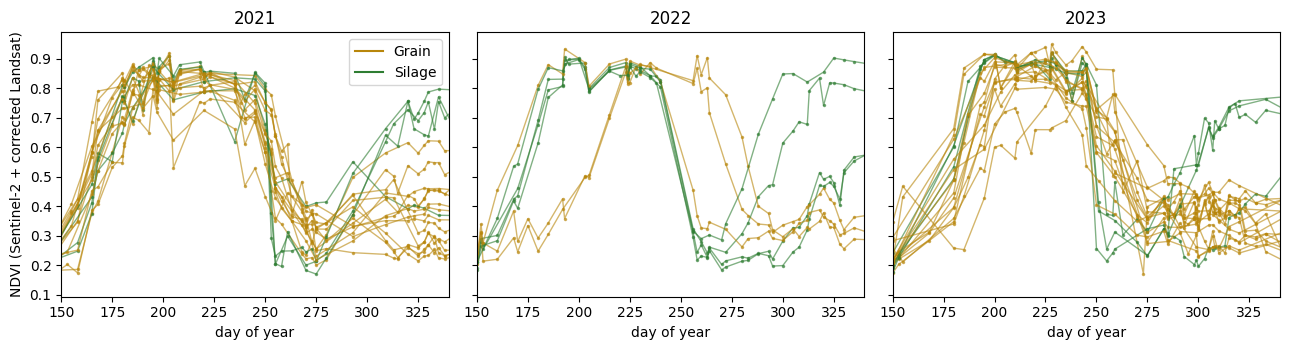

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
colors = {"Grain": "#b8860b", "Silage": "#2e7d32"}
curves = series.merge(labels, on=["field_id", "year"])
for ax, (year, g) in zip(axes, curves.groupby("year")):
    for (fid, kind), f in g.groupby(["field_id", "harvest_type"]):
        ax.plot(f["doy"], f["ndvi"], color=colors[kind], alpha=0.6, lw=1, marker=".", ms=3)
    ax.set_title(str(year)); ax.set_xlabel("day of year"); ax.set_xlim(150, 340)
axes[0].set_ylabel("NDVI (Sentinel-2 + corrected Landsat)")
axes[0].legend(handles=[plt.Line2D([], [], color=c, label=k) for k, c in colors.items()])
plt.tight_layout()

## 3. Validation design

The same field appears in several years, and neighbouring fields share weather. A random split would leak.

- **Leave one year out**: train on two years, test on the third. Answers "does it carry over to a new season?"
- **Grouped by field** (5 folds, stratified): no field is in both train and test.

Every prediction below is out-of-fold: the model that scores a field-year never saw its label.
The series cleaning and the features use no labels, so they are computed once for all fields.
The settings and the 0.5 threshold are fixed in advance, so there is no tuning loop for labels to leak through.


In [7]:
SEEDS = range(10)     # each XGBoost model is the average of 10 seeds


def make_xgb(y_train, seed=SEED):
    pos = max(int(y_train.sum()), 1)
    return XGBClassifier(
        n_estimators=200, max_depth=2, learning_rate=0.05,      # small trees: 44 samples
        subsample=0.8, colsample_bytree=0.8, min_child_weight=1, reg_lambda=1.0,
        scale_pos_weight=(len(y_train) - pos) / pos,             # Silage is the minority
        eval_metric="logloss", random_state=seed, n_jobs=4)


def make_rule(y_train, seed=SEED):
    # One split on the drop date. Rows with no detected drop go to the side the tree learns.
    return DecisionTreeClassifier(max_depth=1, class_weight="balanced", random_state=seed)


def oof_predict(make_model, X, y, splits, seeds=(SEED,)):
    proba = pd.Series(0.0, index=X.index)
    for train, test in splits:
        for seed in seeds:
            model = make_model(y.iloc[train], seed).fit(X.iloc[train], y.iloc[train])
            proba.iloc[test] += model.predict_proba(X.iloc[test])[:, 1] / len(seeds)
    return proba


def report(name, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    print(f"=== {name} ===")
    print(classification_report(y, pred, target_names=["Grain", "Silage"], digits=2, zero_division=0))
    print(pd.DataFrame(confusion_matrix(y, pred), index=["true Grain", "true Silage"],
                       columns=["pred Grain", "pred Silage"]), "\n")
    return pred


def field_splits(seed):
    return list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed).split(X, y, groups=data["field_id"]))


splits = {
    "leave one year out": list(LeaveOneGroupOut().split(X, y, groups=data["year"])),
    "grouped by field": field_splits(SEED),
}
for name, sp in splits.items():
    print(name, "| test sizes:", [len(te) for _, te in sp], "| Silage in test:", [int(y.iloc[te].sum()) for _, te in sp])


leave one year out | test sizes: [18, 7, 19] | Silage in test: [4, 4, 4]
grouped by field | test sizes: [9, 10, 8, 8, 9] | Silage in test: [2, 3, 2, 2, 3]


## 4. Results

In [8]:
RULE_FEATURES = ["drop_doy"]
MODELS = {      # name: (model factory, feature table, seeds)
    "rule: drop_doy": (make_rule, X[RULE_FEATURES], (SEED,)),
    "xgboost, S2 only (first version)": (make_xgb, X_s2_only, SEEDS),
    "xgboost": (make_xgb, X, SEEDS),
    "xgboost + S1 radar": (make_xgb, X_with_s1, SEEDS),
}
preds, probas = {}, {}
for split_name, sp in splits.items():
    for model_name, (make_model, Xm, seeds) in MODELS.items():
        proba = oof_predict(make_model, Xm, y, sp, seeds)
        probas[(model_name, split_name)] = proba
        preds[(model_name, split_name)] = report(f"{model_name} | {split_name}", proba)
    data[f"p_silage_{split_name.replace(' ', '_')}"] = probas[("xgboost", split_name)]


=== rule: drop_doy | leave one year out ===
              precision    recall  f1-score   support

       Grain       0.96      0.81      0.88        32
      Silage       0.65      0.92      0.76        12

    accuracy                           0.84        44
   macro avg       0.81      0.86      0.82        44
weighted avg       0.88      0.84      0.85        44

             pred Grain  pred Silage
true Grain           26            6
true Silage           1           11 



=== xgboost, S2 only (first version) | leave one year out ===
              precision    recall  f1-score   support

       Grain       0.93      0.88      0.90        32
      Silage       0.71      0.83      0.77        12

    accuracy                           0.86        44
   macro avg       0.82      0.85      0.84        44
weighted avg       0.87      0.86      0.87        44

             pred Grain  pred Silage
true Grain           28            4
true Silage           2           10 



=== xgboost | leave one year out ===
              precision    recall  f1-score   support

       Grain       0.91      1.00      0.96        32
      Silage       1.00      0.75      0.86        12

    accuracy                           0.93        44
   macro avg       0.96      0.88      0.91        44
weighted avg       0.94      0.93      0.93        44

             pred Grain  pred Silage
true Grain           32            0
true Silage           3            9 



=== xgboost + S1 radar | leave one year out ===
              precision    recall  f1-score   support

       Grain       0.94      1.00      0.97        32
      Silage       1.00      0.83      0.91        12

    accuracy                           0.95        44
   macro avg       0.97      0.92      0.94        44
weighted avg       0.96      0.95      0.95        44

             pred Grain  pred Silage
true Grain           32            0
true Silage           2           10 

=== rule: drop_doy | grouped by field ===
              precision    recall  f1-score   support

       Grain       0.96      0.81      0.88        32
      Silage       0.65      0.92      0.76        12

    accuracy                           0.84        44
   macro avg       0.81      0.86      0.82        44
weighted avg       0.88      0.84      0.85        44

             pred Grain  pred Silage
true Grain           26            6
true Silage           1           11 



=== xgboost, S2 only (first version) | grouped by field ===
              precision    recall  f1-score   support

       Grain       0.91      0.97      0.94        32
      Silage       0.90      0.75      0.82        12

    accuracy                           0.91        44
   macro avg       0.91      0.86      0.88        44
weighted avg       0.91      0.91      0.91        44

             pred Grain  pred Silage
true Grain           31            1
true Silage           3            9 



=== xgboost | grouped by field ===
              precision    recall  f1-score   support

       Grain       0.97      0.94      0.95        32
      Silage       0.85      0.92      0.88        12

    accuracy                           0.93        44
   macro avg       0.91      0.93      0.92        44
weighted avg       0.93      0.93      0.93        44

             pred Grain  pred Silage
true Grain           30            2
true Silage           1           11 



=== xgboost + S1 radar | grouped by field ===
              precision    recall  f1-score   support

       Grain       0.97      0.91      0.94        32
      Silage       0.79      0.92      0.85        12

    accuracy                           0.91        44
   macro avg       0.88      0.91      0.89        44
weighted avg       0.92      0.91      0.91        44

             pred Grain  pred Silage
true Grain           29            3
true Silage           1           11 



In [9]:
# One table: counts (Silage = positive), precision and recall for both classes, plus two threshold-free scores
# TPR = TP / all Silage, FNR = 1 - TPR, FPR = FP / all Grain, TNR = 1 - FPR
# TP: Silage called Silage | FP: Grain called Silage | FN: Silage called Grain | TN: Grain called Grain
rows = []
for (model, split_name), pred in preds.items():
    rep = classification_report(y, pred, target_names=["Grain", "Silage"], output_dict=True, zero_division=0)
    proba = probas[(model, split_name)]
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()      # Silage is the positive class
    rows.append({"model": model, "split": split_name,
                 "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                 "TPR": tp / (tp + fn), "FNR": fn / (tp + fn), "FPR": fp / (fp + tn), "TNR": tn / (fp + tn),
                 "Grain precision": rep["Grain"]["precision"], "Grain recall": rep["Grain"]["recall"],
                 "Silage precision": rep["Silage"]["precision"], "Silage recall": rep["Silage"]["recall"],
                 "macro F1": rep["macro avg"]["f1-score"],
                 "ROC AUC": roc_auc_score(y, proba), "avg precision": average_precision_score(y, proba)})
summary = pd.DataFrame(rows).set_index(["split", "model"]).sort_index().round(2)
summary


TP  FP  FN  TN   TPR  \
split              model                                                    
grouped by field   rule: drop_doy                    11   6   1  26  0.92   
                   xgboost                           11   2   1  30  0.92   
                   xgboost + S1 radar                11   3   1  29  0.92   
                   xgboost, S2 only (first version)   9   1   3  31  0.75   
leave one year out rule: drop_doy                    11   6   1  26  0.92   
                   xgboost                            9   0   3  32  0.75   
                   xgboost + S1 radar                10   0   2  32  0.83   
                   xgboost, S2 only (first version)  10   4   2  28  0.83   

                                                      FNR   FPR   TNR  \
split              model                                                
grouped by field   rule: drop_doy                    0.08  0.19  0.81   
                   xgboost                           0.08  0.06  0.94   
                   xgboost + S1 radar                0.08  0.09  0.91   
                   xgboost, S2 only (first version)  0.25  0.03  0.97   
leave one year out rule: drop_doy                    0.08  0.19  0.81   
                   xgboost                           0.25  0.00  1.00   
                   xgboost + S1 radar                0.17  0.00  1.00   
                   xgboost, S2 only (first version)  0.17  0.12  0.88   

                                                     Grain precision  \
split              model                                               
grouped by field   rule: drop_doy                               0.96   
                   xgboost                                      0.97   
                   xgboost + S1 radar                           0.97   
                   xgboost, S2 only (first version)             0.91   
leave one year out rule: drop_doy                               0.96   
                   xgboost                                      0.91   
                   xgboost + S1 radar                           0.94   
                   xgboost, S2 only (first version)             0.93   

                                                     Grain recall  \
split              model                                            
grouped by field   rule: drop_doy                            0.81   
                   xgboost                                   0.94   
                   xgboost + S1 radar                        0.91   
                   xgboost, S2 only (first version)          0.97   
leave one year out rule: drop_doy                            0.81   
                   xgboost                                   1.00   
                   xgboost + S1 radar                        1.00   
                   xgboost, S2 only (first version)          0.88   

                                                     Silage precision  \
split              model                                                
grouped by field   rule: drop_doy                                0.65   
                   xgboost                                       0.85   
                   xgboost + S1 radar                            0.79   
                   xgboost, S2 only (first version)              0.90   
leave one year out rule: drop_doy                                0.65   
                   xgboost                                       1.00   
                   xgboost + S1 radar                            1.00   
                   xgboost, S2 only (first version)              0.71   

                                                     Silage recall  macro F1  \
split              model                                                       
grouped by field   rule: drop_doy                             0.92      0.82   
                   xgboost                                    0.92      0.92   
                   xgboost + S1 radar                         0.92      0.89   
        

### How sure are these numbers?

Two checks, both on out-of-fold predictions only:

- **Repeated field splits.** The grouped split above is one random partition. Ten different partitions show how much the score moves with the partition alone.
- **Bootstrap over fields.** Fields are resampled with replacement (all years of a field stay together) to give a 90% interval for macro F1.

One field-year is worth about 0.03 macro F1 here, so differences smaller than that are not evidence.

**Reading the radar row.** Compare `xgboost + S1 radar` with `xgboost` in the tables above and below.
If the difference is within one or two field-years, radar is not adding evidence here. The main model (`xgboost`) stays optical.

In [10]:
def macro_f1(truth, proba):
    return f1_score(truth, proba >= 0.5, average="macro")


rep_rows = []
for model_name in ("xgboost, S2 only (first version)", "xgboost", "xgboost + S1 radar"):
    make_model, Xm, seeds = MODELS[model_name]
    for seed in range(10):
        proba = oof_predict(make_model, Xm, y, field_splits(seed), seeds)
        rep_rows.append({"model": model_name, "split seed": seed, "macro F1": macro_f1(y, proba),
                         "ROC AUC": roc_auc_score(y, proba), "avg precision": average_precision_score(y, proba)})
repeated = pd.DataFrame(rep_rows)
print("Grouped by field, 10 different partitions:")
print(repeated.groupby("model")[["macro F1", "ROC AUC", "avg precision"]].agg(["mean", "std", "min", "max"]).round(3).T, "\n")

rng = np.random.default_rng(SEED)
field_ids = data["field_id"].unique()
rows_of = {f: np.flatnonzero(data["field_id"].values == f) for f in field_ids}
boot_rows = []
for (model_name, split_name), proba in probas.items():
    scores = []
    for _ in range(2000):
        idx = np.concatenate([rows_of[f] for f in rng.choice(field_ids, len(field_ids))])
        if y.values[idx].min() != y.values[idx].max():
            scores.append(macro_f1(y.values[idx], proba.values[idx]))
    boot_rows.append({"split": split_name, "model": model_name, "macro F1": macro_f1(y, proba),
                      "90% low": np.quantile(scores, 0.05), "90% high": np.quantile(scores, 0.95)})
pd.DataFrame(boot_rows).set_index(["split", "model"]).sort_index().round(2)

Grouped by field, 10 different partitions:
model               xgboost  xgboost + S1 radar  \
macro F1      mean    0.907               0.911   
              std     0.030               0.024   
              min     0.866               0.891   
              max     0.943               0.943   
ROC AUC       mean    0.947               0.938   
              std     0.006               0.010   
              min     0.935               0.917   
              max     0.956               0.953   
avg precision mean    0.943               0.931   
              std     0.007               0.018   
              min     0.932               0.890   
              max     0.951               0.950   

model               xgboost, S2 only (first version)  
macro F1      mean                             0.888  
              std                              0.030  
              min                              0.813  
              max                              0.912  
ROC AUC       mean

macro F1  90% low  \
split              model                                                 
grouped by field   rule: drop_doy                        0.82     0.71   
                   xgboost                               0.92     0.83   
                   xgboost + S1 radar                    0.89     0.79   
                   xgboost, S2 only (first version)      0.88     0.77   
leave one year out rule: drop_doy                        0.82     0.72   
                   xgboost                               0.91     0.80   
                   xgboost + S1 radar                    0.94     0.85   
                   xgboost, S2 only (first version)      0.84     0.73   

                                                     90% high  
split              model                                       
grouped by field   rule: drop_doy                        0.91  
                   xgboost                               0.98  
                   xgboost + S1 radar                    0.97  
                   xgboost, S2 only (first version)      0.97  
leave one year out rule: drop_doy                        0.90  
                   xgboost                               0.97  
                   xgboost + S1 radar                    1.00  
                   xgboost, S2 only (first version)      0.92

In [11]:
# By year (XGBoost, leave one year out): the number of fields and how many were right
by_year = data.assign(pred=preds[("xgboost", "leave one year out")])
by_year["correct"] = by_year["pred"] == by_year["y"]
by_year.groupby(["year", "harvest_type"])["correct"].agg(n="size", correct="sum")

n  correct
year harvest_type             
2021 Grain         14       14
     Silage         4        3
2022 Grain          3        3
     Silage         4        4
2023 Grain         15       15
     Silage         4        2

## 5. What the model uses

Fitted on all 44 field-years, for inspection only. Not used for any score above.

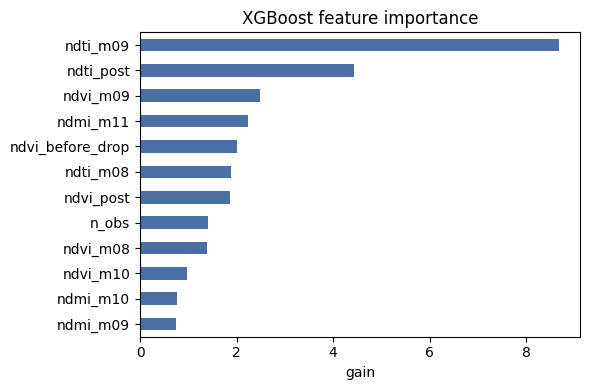

In [12]:
full = make_xgb(y).fit(X, y)
gain = pd.Series(full.get_booster().get_score(importance_type="gain")).sort_values()
gain.tail(12).plot.barh(figsize=(6, 4), color="#4a6fa5")
plt.xlabel("gain"); plt.title("XGBoost feature importance"); plt.tight_layout()

In [13]:
# Errors, for a look at the individual curves
miss = by_year[~by_year["correct"]]
miss[["field_id", "year", "harvest_type", "p_silage_leave_one_year_out", "drop_doy", "ndvi_before_drop",
      "drop_gap_days", "ndti_post", "n_obs"]].round(2)

,field_id,year,harvest_type,p_silage_leave_one_year_out,drop_doy,ndvi_before_drop,drop_gap_days,ndti_post,n_obs
9,327,2021,Silage,0.07,270.0,0.49,9.0,0.17,39
35,292,2023,Silage,0.34,251.0,0.87,6.0,0.14,45
36,323,2023,Silage,0.28,251.0,0.88,6.0,0.15,39
